### Дообучение с небольшим числом обучаемых параметров (PEFT)

В этом ноутбуке вы будете дообучать большие языковые модели при ограниченном объёме видеопамяти. Вы реализуете prompt tuning и LoRA, а также попробуете библиотеку Hugging Face PEFT.



In [ ]:
# %pip install --quiet transformers==4.34.1 accelerate==0.24.0 sentencepiece==0.1.99 optimum==1.13.2 peft==0.5.0 bitsandbytes==0.41.2.post2

%pip install --quiet -U bitsandbytes "transformers>=4.43,<4.46" "accelerate>=0.33,<0.36" peft optimum sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.9/160.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 35.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hu

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
from tqdm.auto import tqdm, trange
assert torch.cuda.is_available(), "Для этой части задания нужен GPU с поддержкой CUDA"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
model_name = 'Enoch/llama-7b-hf'

# Загружаем токенизатор Llama...
tokenizer = transformers.LlamaTokenizer.from_pretrained(model_name, device_map=device)
tokenizer.pad_token_id = tokenizer.eos_token_id

# ...и саму модель
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map='auto',
    low_cpu_mem_usage=True,
    offload_state_dict=True,
    load_in_4bit=True,
    torch_dtype=torch.float32,  # Веса — 4-битные; нормализации и активации — в fp32
)
for param in model.parameters():
    param.requires_grad=False

model.gradient_checkpointing_enable()  # Сохраняем лишь часть активаций, остальные вычисляем повторно
model.enable_input_require_grads()     # Для checkpointing включаем вычисление градиентов по входам, чтобы сохранить обратное распространение
# Подробнее о gradient checkpointing: https://pytorch.org/docs/stable/checkpoint.html https://arxiv.org/abs/1604.06174

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/218 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama.LlamaTokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message


config.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

... (33 outputs left out)

pytorch_model-00032-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00033-of-00033.bin:   0%|          | 0.00/524M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/33 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/151 [00:00<?, ?B/s]

### Prompt tuning: история одной лисы (1 балл)

![Лиса из примера](https://i.imgur.com/Ux3qQAu.png) (источник: theodd1souts.fandom.com)


In [ ]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)

for i in range(10):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\nРезультат:", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()))

Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)



Результат: <s>A quick brown fox jumps over the lazy dog.
A quick


Какая наглая ложь! Эта лиса уверяет, что вовсе не перепрыгивала через ленивую собаку. Она просто занималась своими делами. **Ваша задача — обучить модель говорить правду: сегодня через собаку никто не прыгал.**

> Добавить блок с цитатой



В примере используется начало известной английской панграммы: «A quick brown fox» — «Быстрая бурая лиса». Целевая фраза `the_truth` отрицает привычное продолжение «jumped over the lazy dog». Для обучения используйте именно английские строки из ячеек ниже.


In [ ]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
outputs = model(**batch)

next_word_logits = outputs.logits[:, :-1]
true_next_tokens = batch['input_ids'][:, 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))

print("Потери:", loss)

Потери: tensor(3.0729, device='cuda:0', grad_fn=<NllLossBackward0>)


Однако обучать всю модель мы не можем: только градиенты в формате `float32` заняли бы около 28 ГБ. Вместо этого применим [prompt tuning](https://arxiv.org/abs/2104.08691) — обучение небольшого набора векторов, добавляемых перед эмбеддингами входных токенов. Параметры исходной модели остаются замороженными.

![Схема prompt tuning](https://i.imgur.com/VwNNKnb.png)


In [ ]:
class WordEmbeddingsWithLearnedPrompts(nn.Module):
    """
    Для prompt tuning замените исходный слой эмбеддингов модели этим слоем.
    Он подставляет обучаемые векторы промпта вместо эмбеддингов первых num_prompts токенов.
    """

    def __init__(self, word_embeddings: nn.Embedding, num_prompts: int):
        super().__init__()
        self.original_word_embeddings = word_embeddings
        self.num_prompts = num_prompts
        self.learnable_prompts = nn.Parameter(
            torch.randn(1, num_prompts, word_embeddings.embedding_dim), requires_grad=True
        )

    def forward(self, input_ids: torch.LongTensor):
        # Форма input_ids: [batch_size, seq_length]
        assert input_ids.dtype == torch.int64
        assert input_ids.shape[1] > self.num_prompts
        assert torch.all(input_ids[:, :self.num_prompts] == tokenizer.pad_token_id).item(), (
            "Не забудьте добавить num_prompts PAD-токенов в начало input_ids"
        )

        # Получите эмбеддинги input_ids с помощью исходного слоя
        input_embeddings = self.original_word_embeddings(input_ids)  # Форма: [batch_size, seq_length, embedding_dim]

        # Замените эмбеддинги первых num_prompts токенов обучаемыми векторами промпта
        batch_size = input_ids.shape[0]
        learnable_prompts_expanded = self.learnable_prompts.expand(batch_size, -1, -1).to(input_embeddings.dtype)  # Форма: [batch_size, num_prompts, embedding_dim]
        remaining_embeddings = input_embeddings[:, self.num_prompts:]  # Форма: [batch_size, seq_length - num_prompts, embedding_dim]

        # Объедините обучаемые векторы промпта с эмбеддингами оставшихся токенов
        output_embeddings = torch.cat([learnable_prompts_expanded, remaining_embeddings], dim=1)

        return output_embeddings


In [ ]:
num_prompts = 16
test_emb_layer = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts).to(device)
test_input_ids = tokenizer("a cat say on a may", return_tensors='pt')['input_ids'].to(device)

space_for_prompts = torch.full([len(test_input_ids), num_prompts], fill_value=tokenizer.pad_token_id,
                               dtype=torch.int64, device=device)
test_inputs_with_prompts = torch.cat([space_for_prompts, test_input_ids], dim=1)

with torch.cuda.amp.autocast():
  test_prompt_embeddings = test_emb_layer(test_inputs_with_prompts)

assert test_prompt_embeddings.shape[:2] == test_inputs_with_prompts.shape
assert test_prompt_embeddings.shape[-1] == model.config.hidden_size
assert torch.allclose(test_prompt_embeddings[:, :num_prompts], test_emb_layer.learnable_prompts.float())
assert torch.allclose(test_prompt_embeddings[:, num_prompts:], model.model.embed_tokens(test_input_ids).float())
print("Проверки пройдены!")

Проверки пройдены!


/tmp/ipykernel_6416/1768851122.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


**Теперь, когда слой работает,** добавим обучаемые векторы промпта в основную модель и научим её рассказывать правду о лисе.


In [ ]:
assert isinstance(model.model.embed_tokens, nn.Embedding), "Вы уже заменили слой эмбеддингов. Если новая реализация работает неверно, заново загрузите модель"

model.model.embed_tokens = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts).to(device)

opt = torch.optim.Adam([model.model.embed_tokens.learnable_prompts], lr=0.01)

In [ ]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
space_for_prompts = torch.full([len(test_input_ids), num_prompts], fill_value=tokenizer.pad_token_id,
                               dtype=torch.int64, device=device)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)

outputs = model(**batch)
next_word_logits = outputs.logits[:, num_prompts : -1, :]
true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
print("Потери:", loss)


num_epochs = 100
for epoch in range(num_epochs):
    outputs = model(**batch)

    next_word_logits = outputs.logits[:, num_prompts:-1, :]
    true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
    loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))

    opt.zero_grad()
    loss.backward()
    opt.step()

    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {loss.item()}")
    if loss.item() < 0.1:
        print("Loss threshold reached. Stopping training.")
        break

Потери: tensor(8.4260, device='cuda:0', grad_fn=<NllLossBackward0>)
Epoch 1/100, Loss: 8.425995826721191
Epoch 2/100, Loss: 7.3602399826049805
Epoch 3/100, Loss: 6.649923324584961
Epoch 4/100, Loss: 5.111364364624023
Epoch 5/100, Loss: 4.311802864074707
Epoch 6/100, Loss: 4.0522141456604
Epoch 7/100, Loss: 3.844829797744751
Epoch 8/100, Loss: 3.557425022125244
Epoch 9/100, Loss: 3.098536491394043
Epoch 10/100, Loss: 2.854740858078003
Epoch 11/100, Loss: 2.7768211364746094
Epoch 12/100, Loss: 2.705430746078491
Epoch 13/100, Loss: 2.63114070892334
Epoch 14/100, Loss: 2.559535264968872
Epoch 15/100, Loss: 2.492658853530884
Epoch 16/100, Loss: 2.430664539337158
Epoch 17/100, Loss: 2.3730757236480713
Epoch 18/100, Loss: 2.3188517093658447
Epoch 19/100, Loss: 2.2661969661712646
Epoch 20/100, Loss: 2.212986946105957
Epoch 21/100, Loss: 2.1574196815490723
Epoch 22/100, Loss: 2.0982275009155273
Epoch 23/100, Loss: 2.034548759460449
Epoch 24/100, Loss: 1.965826153755188
Epoch 25/100, Loss: 1.892

In [ ]:
# Итоговая проверка значения потерь
assert loss.item() <= 0.1
print("Отлично!")

Отлично!


In [ ]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)


for i in range(15):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\nРезультат:", tokenizer.decode(batch['input_ids'][0, num_prompts:].cpu().numpy().tolist()))

# Если всё сделано верно, модель будет отрицать, что лиса перепрыгнула через ленивую собаку


Результат: <s>A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it


### Используем Hugging Face PEFT (2 балла)

[`peft`](https://huggingface.co/docs/peft/index) — библиотека для дообучения предобученных трансформеров с небольшим числом обучаемых параметров (**P**arameter **E**fficient **F**ine-**T**uning). Она предоставляет общий интерфейс для prompt tuning, prefix tuning и нескольких методов на основе адаптеров.

Перед выполнением следующей ячейки заново загрузите исходную модель из начала ноутбука: здесь нужен исходный слой эмбеддингов, без вашей обёртки `WordEmbeddingsWithLearnedPrompts`.


In [ ]:
import gc
for name in ['model', 'test_emb_layer', 'opt', 'outputs', 'loss', 'next_word_logits', 'batch']:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name, device_map='auto', low_cpu_mem_usage=True, offload_state_dict=True,
    load_in_4bit=True, torch_dtype=torch.float32,
)
for param in model.parameters():
    param.requires_grad = False
model.gradient_checkpointing_enable()
model.enable_input_require_grads()

In [ ]:
import peft
assert isinstance(model.model.embed_tokens, nn.Embedding), "Заново загрузите исходную модель"

peft_config = peft.PromptTuningConfig(task_type=peft.TaskType.CAUSAL_LM, num_virtual_tokens=16)
model = peft.get_peft_model(model, peft_config)  # Для большинства методов PEFT этот вызов также изменяет исходный объект model
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Всего параметров (без учёта квантования):", sum(p.numel() for p in model.parameters()))

Обучаемых параметров: 65536
Всего параметров (без учёта квантования): 3500478464


In [ ]:
# Задание: обучите модель с обёрткой PEFT так, чтобы потери при предсказании следующего токена стали меньше 0.1
# PAD-токены вручную добавлять больше не нужно, но первые num_virtual_tokens позиций logits нужно пропустить
# В конце сгенерируйте продолжение фразы и убедитесь, что модель усвоила правду

In [ ]:
# Задаём целевую фразу
# the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors="pt", return_token_type_ids=False).to(device)

In [ ]:
# Настройки обучения
loss_threshold = 0.1  # Целевой порог потерь
num_epochs = 100  # Максимальное число эпох
learning_rate = 0.01  # Скорость обучения

# Создайте оптимизатор для обучаемых параметров — векторов промпта PEFT
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr = learning_rate
)

# Задаём целевую фразу
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors="pt", return_token_type_ids=False).to(device)

num_virtual_tokens = peft_config.num_virtual_tokens

# Цикл обучения
for epoch in range(num_epochs):
    # Прямой проход
    outputs = model(**batch)

    # Пропустите logits для виртуальных токенов и последнего токена
    next_word_logits = outputs.logits[:, num_virtual_tokens:-1, :]  # Пропускаем виртуальные токены
    true_next_tokens = batch['input_ids'][:, 1:]  # Сдвигаем целевые токены на одну позицию

    # Вычисляем потери
    loss = F.cross_entropy(
        next_word_logits.flatten(0,1),
        true_next_tokens.flatten(0,1)
    )

    # Обратное распространение и обновление параметров
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Выводим потери, чтобы отслеживать обучение
    print(f"Эпоха {epoch + 1}/{num_epochs}, потери: {loss.item()}")

    # Останавливаем обучение, если потери ниже порога
    if loss.item() < loss_threshold:
        print("Целевой порог потерь достигнут. Останавливаем обучение.")
        break
else:
    print("Достигнуто максимальное число эпох; целевой порог потерь ещё не достигнут.")

Эпоха 1/100, потери: 7.854222297668457
Эпоха 2/100, потери: 7.0568389892578125
Эпоха 3/100, потери: 6.398674011230469
Эпоха 4/100, потери: 5.669889450073242
Эпоха 5/100, потери: 5.105601787567139
Эпоха 6/100, потери: 4.771571636199951
Эпоха 7/100, потери: 4.538772106170654
Эпоха 8/100, потери: 4.3275909423828125
Эпоха 9/100, потери: 4.113471508026123
Эпоха 10/100, потери: 3.8760826587677
Эпоха 11/100, потери: 3.622401475906372
Эпоха 12/100, потери: 3.3781065940856934
Эпоха 13/100, потери: 3.12237548828125
Эпоха 14/100, потери: 2.927504062652588
Эпоха 15/100, потери: 2.816216230392456
Эпоха 16/100, потери: 2.7058255672454834
Эпоха 17/100, потери: 2.5911927223205566
Эпоха 18/100, потери: 2.4865081310272217
Эпоха 19/100, потери: 2.3961241245269775
Эпоха 20/100, потери: 2.312647819519043
Эпоха 21/100, потери: 2.2336056232452393
Эпоха 22/100, потери: 2.160660743713379
Эпоха 23/100, потери: 2.0976545810699463
Эпоха 24/100, потери: 2.0420682430267334
Эпоха 25/100, потери: 1.9894877672195435
Э

In [ ]:
# Итоговая проверка: потери должны быть ниже порога
assert loss.item() < loss_threshold, "Не удалось снизить потери ниже заданного порога."
print("Обучение завершено успешно! Потери ниже 0.1.")

Обучение завершено успешно! Потери ниже 0.1.


In [ ]:
prompt = "A quick brown fox"
batch = tokenizer(prompt, return_tensors="pt", return_token_type_ids=False).to(device)

# Генерируем 15 токенов
for i in range(15):
    # Прямой проход для получения logits
    outputs = model(**batch)
    next_token = outputs.logits[0, -1].argmax(-1).reshape(1, 1)

    # Добавляем следующий токен к input_ids
    batch["input_ids"] = torch.cat([batch["input_ids"], next_token], dim=-1)

    # Дополняем attention_mask, чтобы её длина совпадала с новой длиной input_ids
    new_attention_mask = torch.ones_like(next_token, dtype=batch["attention_mask"].dtype).to(device)
    batch["attention_mask"] = torch.cat([batch["attention_mask"], new_attention_mask], dim=-1)

# Декодируем сгенерированную последовательность
# Здесь виртуальные токены добавляет PEFT внутри модели; в batch["input_ids"] их нет
decoded_output = tokenizer.decode(batch["input_ids"][0].cpu().numpy().tolist(), skip_special_tokens=True)
print("\nРезультат:", decoded_output)



Результат: A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it


### Дообучение с помощью LoRA (2 балла)

Для более содержательных задач можно использовать адаптеры низкого ранга из [статьи о LoRA](https://arxiv.org/pdf/2106.09685.pdf).

Основная идея — добавить обучаемый адаптер низкого ранга **параллельно существующему линейному слою** и сложить их выходы:
<center><img src="https://i.imgur.com/6bQLNiG.png" width=240px></center>

В исходной статье LoRA адаптеры добавляли только к матрицам проекций механизма внимания. Однако [последующие работы](https://arxiv.org/abs/2305.14314) показывают, что полезно адаптировать и полносвязные блоки (FFN). Прежде чем обучать модель, реализуйте базовый слой LoRA.


In [ ]:
# Заново загружаем модель без ранее добавленных адаптеров PEFT
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name, device_map='auto', low_cpu_mem_usage=True, offload_state_dict=True,
    load_in_4bit=True, torch_dtype=torch.float32,  # Веса — 4-битные; нормализации и активации — в fp32
)
for param in model.parameters():
    param.requires_grad=False
model.gradient_checkpointing_enable()
model.enable_input_require_grads()

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.


Loading checkpoint shards:   0%|          | 0/33 [00:00<?, ?it/s]

In [ ]:
class LoRALayer(nn.Module):
    """Добавляет LoRA-адаптер к существующему линейному слою."""
    def __init__(self, module: nn.Linear, rank: int):
        super().__init__()
        self.module = module  # Предобученный замороженный линейный слой
        self.adapter_A = nn.Parameter(torch.empty(module.in_features, rank, device=module.weight.device))
        nn.init.kaiming_uniform_(self.adapter_A, a=5 ** 0.5)
        self.adapter_B = nn.Parameter(torch.zeros(rank, module.out_features, device=module.weight.device))

    def forward(self, input):
        # Примените self.module и LoRA-адаптер к входу, затем верните сумму их выходов
        original_output = self.module(input)
        lora_output = (input @ self.adapter_A) @ self.adapter_B

        return original_output + lora_output

In [ ]:
# Проверяем вашу реализацию
test_linear = nn.Linear(128, 128)
test_linear.weight.data[...] = torch.eye(128)
test_adapter = LoRALayer(test_linear, rank=8)

assert torch.allclose(test_adapter(torch.ones(1, 1, 128)), test_linear.bias + 1), "Проверьте реализацию прямого прохода"

test_adapter.adapter_A.data[...] = torch.linspace(0.1, -0.5, 128 * 8).view(128, 8)
test_adapter.adapter_B.data[...] = torch.linspace(0.5, -0.1, 128 * 8).view(8, 128)
test_linear.bias.data[...] = torch.linspace(1., -1., 128)

dummy_loss = F.mse_loss(test_adapter(torch.ones(1, 128) / 128).squeeze(), torch.linspace(-1, 1, 128))
assert torch.allclose(dummy_loss, torch.tensor(1.3711389), rtol=0, atol=1e-4)
dummy_loss.backward()
assert all(w.grad is not None for w in [test_adapter.adapter_A, test_adapter.adapter_B]), "Для некоторых параметров адаптера не вычислен градиент"
assert torch.allclose(test_adapter.adapter_A.grad.sum(), torch.tensor(-0.60158), rtol=0, atol=1e-4), "Неверный градиент по матрице A"
assert torch.allclose(test_adapter.adapter_B.grad.sum(), torch.tensor(0.9931), rtol=0, atol=1e-4), "Неверный градиент по матрице B"
# Неверный градиент: реализация отличается от формулы LoRA или нарушено вычисление градиентов (например, используется no_grad)
del dummy_loss, test_linear, test_adapter
print("Все проверки пройдены!")

Все проверки пройдены!


### Добавляем LoRA в модель

Код ниже добавляет LoRA-адаптеры к линейным проекциям Q/K/V в механизме внимания Llama. Можно также модифицировать другие слои:

* `self_attn.o_proj` — выходную проекцию механизма внимания;
* `mlp.up_proj`, `mlp.gate_proj`, `mlp.down_proj` — полносвязные слои трансформера;
* `lm_head` — выходной слой языковой модели.

Проверка в следующей ячейке ожидает 96 адаптеров: по три проекции Q/K/V в каждом из 32 блоков Llama-7B. Дополнительные адаптеры для итогового задания добавляйте после этой проверки.


In [ ]:
lora_rank = 8

for name, module in model.model.layers.named_modules():
    if 'LlamaDecoderLayer' in repr(type(module)):
        module.self_attn.q_proj = LoRALayer(module.self_attn.q_proj, rank=lora_rank).to(device)
        module.self_attn.k_proj = LoRALayer(module.self_attn.k_proj, rank=lora_rank).to(device)
        module.self_attn.v_proj = LoRALayer(module.self_attn.v_proj, rank=lora_rank).to(device)

assert sum(isinstance(module, LoRALayer) for module in model.modules()) == 96  # Для Llama-7B

In [ ]:
batch = tokenizer("This model wants to share its greatest secret:", return_tensors='pt', return_token_type_ids=False)
# Проверяем один шаг обучения: градиенты должны быть ненулевыми
with torch.cuda.amp.autocast(dtype=torch.float32):
    out = model.forward(**batch)
    (out.logits.norm() / 100).backward()

for i, module in enumerate(model.modules()):
    if isinstance(module, LoRALayer):
        assert module.adapter_B.grad is not None
        assert module.adapter_B.grad.norm().item() > 0

model.zero_grad(set_to_none=True)
print("Проверка градиентов пройдена, отлично!")

/tmp/ipykernel_6416/495728678.py:3: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float32):


Проверка градиентов пройдена, отлично!


### Пример обучения модели

Пример ниже показывает, как обучать LoRA-адаптеры на небольшом демонстрационном датасете. В итоговом задании вам предстоит организовать похожее обучение.

**Обратите внимание:** условия итогового задания находятся ниже. Эта ячейка — только пример.


In [ ]:
# Проверяем, способна ли модель обучаться. Для полноценного обучения измените max_steps
import datasets
data = datasets.load_dataset("Abirate/english_quotes", split="train[:32]") # 32 примера
data = data.map(lambda samples: tokenizer(samples['quote']), batched=True)
model._hf_peft_config_loaded = True  # Отключаем предупреждение Trainer из Hugging Face

trainer = transformers.Trainer(
    model=model, train_dataset=data,
    args=transformers.TrainingArguments(
        per_device_train_batch_size=2,
        gradient_accumulation_steps=1, # Накопление градиентов увеличивает эффективный размер батча
        warmup_steps=250,
        max_steps=100,
        learning_rate=2e-4,
        fp16=True,
        logging_steps=1,
        output_dir='outputs',
        report_to=None,
        save_strategy="no" # Для совместимости по состоянию на октябрь 2025 года (спасибо Владу!)
    ),
    data_collator=transformers.DataCollatorForLanguageModeling(tokenizer, mlm=False)
)
# При предупреждениях о кэше задайте model.config.use_cache = False. Перед генерацией включите кэш обратно!

trainer.train()

# Это только пример: можно прервать его, не дожидаясь завершения обучения :)

README.md: 0.00B [00:00, ?B/s]

quotes.jsonl:   0%|          | 0.00/647k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2508 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
max_steps is given, it will override any value given in num_train_epochs
wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss
1,1.271700
2,0.377700
3,1.469600
4,1.434500
5,0.860800
6,1.661600
7,1.871700
8,1.270800
9,0.560300
10,1.284800


TrainOutput(global_step=100, training_loss=0.5427741277962923, metrics={'train_runtime': 174.584, 'train_samples_per_second': 1.146, 'train_steps_per_second': 0.573, 'total_flos': 634829603291136.0, 'train_loss': 0.5427741277962923, 'epoch': 6.25})

Спасибо, что показали что такое wandb, это имба прямо. Но в финальной версии я выключил визуализацию, на всякий случай )

### Итоговое задание: обучаем модель на практике (5 баллов)

Ваша задача — дообучить модель **генерировать код на Python**. Используйте предыдущие примеры как основу.

* **Данные:** используйте [codeparrot-clean](https://huggingface.co/datasets/codeparrot/codeparrot-clean) или другой датасет с кодом на Python. Для этого упражнения достаточно небольшой части обучающей выборки.
* **Предобработка:** оставьте файлы с расширением `.py`. Для `codeparrot-clean` этот шаг можно пропустить: он уже содержит код на Python.
* **Длина примеров:** возьмите первые 512 символов каждого примера. Здесь ограничение задано в символах, а не в токенах.
* **Адаптеры:** используйте реализованную выше LoRA **и хотя бы одно** из следующих дополнений:
  - адаптер для `lm_head`;
  - адаптеры для компонентов MLP (`mlp.*`);
  - обучаемые входные эмбеддинги (потребуется скорректировать использование памяти).
* **Обучение:** обучать модель до сходимости не обязательно. Ориентир — 500 шагов: после этого проверьте, генерирует ли модель код методом `.generate()`. Используйте эффективный размер батча не меньше 4 и накопление градиентов `gradient_accumulation_steps=4`. Эффективный размер батча равен `per_device_train_batch_size × gradient_accumulation_steps × число GPU`.

В библиотеке `peft` тоже есть реализация LoRA. Однако для этого задания нужно показать **хотя бы один полный запуск обучения с вашей собственной реализацией LoRA**.

**Альтернативное задание:** вместо генерации кода на Python можно выбрать другой датасет и задачу, например тексты любимого исполнителя или расшифровки подкаста, если такое использование данных этично. Покажите на примерах, чему модель научилась — или не научилась, — сравнив генерации до и после дообучения, как в шаблоне ниже.


In [4]:
from datasets import load_dataset, Dataset

NUM_EXAMPLES = 5000
MAX_CHARS = 512
MAX_TOKENS = 256

stream = load_dataset("codeparrot/codeparrot-clean", split="train", streaming=True)

rows = []
for ex in stream:
    text = ex["content"][:MAX_CHARS]
    if len(text.strip()) >= 50:
        rows.append({"text": text})
    if len(rows) >= NUM_EXAMPLES:
        break

def mostly_code(text):
    lines = [l for l in text.splitlines() if l.strip()]
    if not lines:
        return False
    comments = sum(l.lstrip().startswith('#') for l in lines)
    return comments / len(lines) < 0.5

print("Собрано до фильтра:", len(rows))
rows = [r for r in rows if mostly_code(r["text"])]
print("После фильтра:", len(rows))

print("Примеров собрано:", len(rows))
print("Пример:\n", rows[0]["text"][:300])

data = Dataset.from_list(rows)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_TOKENS)

data = data.map(tokenize, batched=True, remove_columns=["text"])

print(data)
print("Средняя длина в токенах:", sum(len(x) for x in data["input_ids"]) / len(data))

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Собрано до фильтра: 5000
После фильтра: 3186
Примеров собрано: 3186
Пример:
 from itertools import chain

from django.utils.itercompat import is_iterable


class Tags:
    """
    Built-in tags for internal checks.
    """
    admin = 'admin'
    caches = 'caches'
    compatibility = 'compatibility'
    database = 'database'
    models = 'models'
    security = 'security'
  


Map:   0%|          | 0/3186 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask'],
    num_rows: 3186
})
Средняя длина в токенах: 165.8515379786566


In [5]:
from torch import nn

has_peft = hasattr(model, "peft_config")
has_lora = any(m.__class__.__name__ == "LoRALayer" for m in model.modules())
emb_ok = isinstance(model.model.embed_tokens, nn.Embedding)

print("PEFT-обёртка:", has_peft)        # должно быть False
print("LoRA-слои:", has_lora)           # должно быть False
print("Эмбеддинги обычные:", emb_ok)    # должно быть True
print("Занято GPU, ГБ:", torch.cuda.memory_allocated() / 1e9)  # ~4.5-5

PEFT-обёртка: False
LoRA-слои: False
Эмбеддинги обычные: True
Занято GPU, ГБ: 4.709302784


In [6]:
prompts =  ['', 'import', 'from', 'while', 'try', 'if', 'for', 'torch', 'write program in python to print "hello world"', 'create a class human']  # Можно добавить другие промпты, в том числе не связанные напрямую с Python

def generate(prompt, max_new_tokens=100):
    model.eval()
    inputs = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             repetition_penalty=1.1, use_cache=True,
                             pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True)

before = {p: generate(p) for p in prompts}
for p in prompts:
    print(f"--- {repr(p)} ---\n{before[p]}\n")

import json
json.dump(before, open('before.json', 'w'), ensure_ascii=False)


Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)


--- '' ---
▶▶ 2019-2020 School Year
The 2019-2020 school year is here! We are so excited to welcome our new students and families into the CIS community. If you have any questions about your child’s transition, please contact us at 651-748-3100 or email us at info@cismn.org.
CIS MN is a nonprofit organization that

--- 'import' ---
import Foundation
import UIKit

class ViewController: UIViewController {
    
    @IBOutlet weak var label: UILabel!
    
    override func viewDidLoad() {
        super.viewDidLoad()
        
        // Do any additional setup after loading the view, typically from a nib.
        
        label.text = "Hello World!"
    }
    
}

--- 'from' ---
from __future__ import absolute_import
from __future__ import division
from __future__ import print_function

import os
import sys

from absl import flags

from tensorflow.python import pywrap_tensorflow as tf


def main(unused_argv):
  """Main function for the test."""

  # The test expects to be run in a virtual en

In [7]:
# <A WHOLE LOT OF YOUR CODE>
# До дообучения сгенерируйте исходные примеры для выбранных промптов
# Используйте transformers.Trainer, как в примере выше, или собственный код обучения
# После обучения покажите генерации модели: ожидаются фрагменты кода на Python
# Для удобства сравнения оформите генерации в таблицу, например с помощью pandas или HTML
# Модель с LoRA генерирует текст тем же способом, что и исходная модель в примерах выше

class LoRALayer(nn.Module):
    """Добавляет LoRA-адаптер к существующему линейному слою."""
    def __init__(self, module: nn.Linear, rank: int):
        super().__init__()
        self.module = module  # Предобученный замороженный линейный слой
        self.adapter_A = nn.Parameter(torch.empty(module.in_features, rank, device=module.weight.device))
        nn.init.kaiming_uniform_(self.adapter_A, a=5 ** 0.5)
        self.adapter_B = nn.Parameter(torch.zeros(rank, module.out_features, device=module.weight.device))

    def forward(self, input):
        # Примените self.module и LoRA-адаптер к входу, затем верните сумму их выходов
        original_output = self.module(input)
        lora_output = (input @ self.adapter_A) @ self.adapter_B

        return original_output + lora_output

lora_rank = 8

for name, module in model.model.layers.named_modules():
    if 'LlamaDecoderLayer' in repr(type(module)):
        module.self_attn.q_proj = LoRALayer(module.self_attn.q_proj, rank=lora_rank).to(device)
        module.self_attn.k_proj = LoRALayer(module.self_attn.k_proj, rank=lora_rank).to(device)
        module.self_attn.v_proj = LoRALayer(module.self_attn.v_proj, rank=lora_rank).to(device)

assert sum(isinstance(module, LoRALayer) for module in model.modules()) == 96  # Для Llama-7B


for name, module in model.model.layers.named_modules():
    if 'LlamaDecoderLayer' in repr(type(module)):
        module.mlp.gate_proj = LoRALayer(module.mlp.gate_proj, rank=lora_rank).to(device)
        module.mlp.up_proj   = LoRALayer(module.mlp.up_proj,   rank=lora_rank).to(device)
        module.mlp.down_proj = LoRALayer(module.mlp.down_proj, rank=lora_rank).to(device)

print("LoRA-слоёв:", sum(isinstance(m, LoRALayer) for m in model.modules()))  # 192
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters() if p.requires_grad))

LoRA-слоёв: 192
Обучаемых параметров: 17891328


In [8]:
model._hf_peft_config_loaded = True
model.config.use_cache = False

trainer = transformers.Trainer(
    model=model, train_dataset=data,
    args=transformers.TrainingArguments(
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        warmup_steps=50,
        max_steps=500,
        learning_rate=2e-4,
        fp16=True,
        logging_steps=10,
        output_dir='outputs',
        report_to="none",
        save_strategy="no",
        seed=42,
    ),
    data_collator=transformers.DataCollatorForLanguageModeling(tokenizer, mlm=False),
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
max_steps is given, it will override any value given in num_train_epochs


Step,Training Loss
10,1.578800
20,1.465500
30,1.516800
40,1.538900
50,1.545700
60,1.457800
70,1.369100
80,1.351200
90,1.429500
100,1.259100


TrainOutput(global_step=500, training_loss=1.3286138553619384, metrics={'train_runtime': 2960.6077, 'train_samples_per_second': 0.676, 'train_steps_per_second': 0.169, 'total_flos': 1.3153224689491968e+16, 'train_loss': 1.3286138553619384, 'epoch': 0.6277463904582549})

In [9]:
model.config.use_cache = True
after = {p: generate(p) for p in prompts}

import json
json.dump(after, open('after.json', 'w'), ensure_ascii=False)

In [15]:
# Этот шаблон позволяет сравнить сгенерированные примеры кода в таблице
# Можно оформить результаты другим удобным способом

import pandas as pd
from IPython.display import display

df = pd.DataFrame({
    "ПРОМПТ": [repr(p) for p in prompts],
    "ДО ОБУЧЕНИЯ": [before[p] for p in prompts],
    "ПОСЛЕ ОБУЧЕНИЯ": [after[p] for p in prompts],
})

styled = (
    df.style
      .set_properties(**{
          "white-space": "pre-wrap",
          "text-align": "left",
          "vertical-align": "top",
          "font-family": "monospace",
          "font-size": "12px",
          "border": "1px solid black",
      })
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "center"), ("border", "1px solid black")]},
          {"selector": "td", "props": [("max-width", "450px")]},
      ])
      .hide(axis="index")
)

display(styled)

ПРОМПТ,ДО ОБУЧЕНИЯ,ПОСЛЕ ОБУЧЕНИЯ
'',"▶▶ 2019-2020 School Year The 2019-2020 school year is here! We are so excited to welcome our new students and families into the CIS community. If you have any questions about your child’s transition, please contact us at 651-748-3100 or email us at info@cismn.org. CIS MN is a nonprofit organization that","# -*- coding: utf-8 -*- """""" werkzeug.contrib.cache ~~~~~~~~~~~~~~~~~~~~~~ This module provides a simple cache backend that stores data in memory. :copyright: (c) 2014 by the Werkzeug Team, see AUTHORS for more details. :license: BSD, see LICENSE for more details. """""" import os"
'import',"import Foundation import UIKit class ViewController: UIViewController { @IBOutlet weak var label: UILabel! override func viewDidLoad() { super.viewDidLoad() // Do any additional setup after loading the view, typically from a nib. label.text = ""Hello World!"" } }","import os import sys from setuptools import setup, find_packages here = os.path.abspath(os.path.dirname(__file__)) with open(os.path.join(here, 'README.rst')) as f: README = f.read() with open(os.path.join(here, 'CHANGES.txt')) as f: CHANGES = f.read()"
'from',"from __future__ import absolute_import from __future__ import division from __future__ import print_function import os import sys from absl import flags from tensorflow.python import pywrap_tensorflow as tf def main(unused_argv): """"""Main function for the test."""""" # The test expects to be run in a virtual environment, so we need to # ensure that the","from __future__ import absolute_import from .common import InfoExtractor from ..utils import ( ExtractorError, unescapeHTML, ) class TmdbIE(InfoExtractor): _VALID_URL = r'https?://(?:www\.)?tmdb\.com/video/[^#]+' _TESTS = [{ 'url': 'http://www.tmdb.com/"
'while',"while(1) while(1) { // do something } \end{code} Comment: This is not the same as the OP's code. Answer: \begin{blockquote} I want to know if there are any differences between these two codes? \end{blockquote} Yes, there are some differences. The first one will run forever (unless you exit it). The second one will stop after 1","while True: try: print(""Enter a number between 1 and 20"") num = int(input()) except ValueError as e: print(""Invalid input. Try again."") continue if num < 1 or num > 20: print(""Invalid input. Try again."") continue print(""You entered %d"" % num) \end{code} Comment: I"
'try',"try to find the best solution for your needs. We are a team of professionals with many years of experience in the field of web development and design, we have created this site to share our knowledge and expertise with you. We hope that you will be able to use it as a reference or source of inspiration.","try: from cStringIO import StringIO except ImportError: from StringIO import StringIO import os from django.conf import settings from django.core.management.base import BaseCommand, CommandError from django.db import connection from django.utils.encoding import force_unicode from django.utils.six.moves import input from django.utils.six.moves import urllib2 class Command(BaseCommand"
'if',"if ( !window.atmosphere ) { window.atmosphere = {}; } (function () { var o = atmosphere.util, atmosphere = atmosphere.atmosphere = function () { // https://github.com/FreMyEr/atmosphere-ios/issues/2 // http://www.w3.org/TR/html5/infrastructure.html#websocket var WebSocket",if (typeof(window) === 'undefined') { var window = this; } if (typeof(require) !== 'function') { require = function() {}; } var _ = require('underscore'); var $ = require('jquery'); var Backbone = require('backbone'); var BaseView = require('./base_view.js'); var utils = require('../utils/utils.js'); var template =
'for',"for the 2019-2020 school year. The application process is now open! Please note that the application deadline has been extended to March 31, 2019. We are currently accepting applications for the 2019-2020 school year. Please click here to apply online or download an application below.","for i in ra

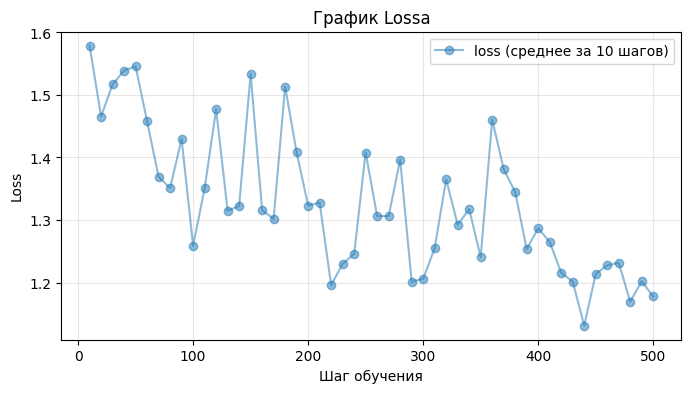

In [13]:
import matplotlib.pyplot as plt
import numpy as np

hist = [(h['step'], h['loss']) for h in trainer.state.log_history if 'loss' in h]
steps, losses = zip(*hist)

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, marker='o', alpha=0.5, label='loss (среднее за 10 шагов)')


plt.xlabel('Шаг обучения')
plt.ylabel('Loss')
plt.title('График Lossa')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Если вы дошли до этого места — поздравляем! Вы выполнили все основные задания.

**Дополнительное задание (бонус):** попробуйте реализовать обучение префиксов, передаваемых в механизм внимания через `model.forward(..., past_key_values=your_prompts)`. О вариантах обучения промптов и префиксов можно прочитать в статьях [1](https://arxiv.org/abs/2104.08691) и [2](https://arxiv.org/abs/2101.00190).

### Дополнительные материалы

* [Квантование после обучения](https://arxiv.org/abs/2208.07339)
* [Запуск больших моделей с помощью Accelerate](https://huggingface.co/docs/accelerate/package_reference/big_modeling)
* [Библиотека адаптеров AdapterHub](https://adapterhub.ml/)

### Запуск других моделей

Этот подход можно адаптировать к другим моделям сопоставимого размера, например [Falcon-7B](https://huggingface.co/tiiuae/falcon-7b), [OPT-6.7B](https://huggingface.co/facebook/opt-6.7b) или [BLOOM-7.1B](https://huggingface.co/bigscience/bloom-7b1). Потребуются небольшие изменения кода:

1. Измените имя модели в `AutoModelForCausalLM.from_pretrained()` и загрузите подходящий токенизатор через `AutoTokenizer`.
2. В коде prompt tuning замените `model.model.embed_tokens` на путь к слою эмбеддингов выбранной модели. Найти его поможет `print(model)`.
3. Адаптируйте код добавления LoRA-слоёв: названия блоков трансформера и их компонентов у других моделей отличаются.
